# Tugas 3 — Visualisasi Data dengan Matplotlib
Dataset: `paket_a_transaksi_pos_2024_2025.csv`

| Bagian | Visualisasi | Jenis grafik |
|---|---|---|
| 1 | Penjualan per bulan tahun 2025 | Line chart |
| 2 | 10 produk terlaris tahun 2025 | Horizontal bar chart |
| 3 | Proporsi transaksi berhasil vs gagal/cancel tahun 2025 | Pie chart |
| 4 | Hubungan jumlah beli dengan diskon | Scatter + boxplot |

## 0. Persiapan & pembersihan data
Aturan pembersihan sama dengan Tugas 1 (ringkas): hapus duplikat, rapikan tanggal/harga/kode produk, kasir kosong diisi, `jumlah` negatif dijadikan positif.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
})

def rupiah_juta(x):           # 12.345.678 -> '12,3 jt'
    return f'{x/1e6:,.1f} jt'.replace(',', 'X').replace('.', ',').replace('X', '.')

In [2]:
df = pd.read_csv('../data/raw/paket_a_transaksi_pos_2024_2025.csv', dtype=str)

df = df.drop_duplicates().reset_index(drop=True)
df['kode_kasir']  = df['kode_kasir'].fillna('TIDAK_DIKETAHUI')
df['kode_produk'] = df['kode_produk'].str.strip().str.upper()
df['status']      = df['status'].str.strip().str.upper()

def parse_tanggal(s):
    s = s.strip()
    if s[4] == '-':
        return pd.to_datetime(s, format='%Y-%m-%d')
    if '/' in s:
        return pd.to_datetime(s, format='%d/%m/%Y')
    return pd.to_datetime(s, format='%d-%m-%Y')

df['tanggal'] = df['tanggal'].apply(parse_tanggal)
df['tahun'] = df['tanggal'].dt.year
df['bulan'] = df['tanggal'].dt.month

df['harga_satuan'] = (df['harga_satuan'].str.replace(',00', '', regex=False)
                                         .str.replace('.', '', regex=False).astype(float))
df['diskon_persen'] = df['diskon_persen'].astype(float)
df['jumlah'] = pd.to_numeric(df['jumlah']).abs()
df['pendapatan'] = df['jumlah'] * df['harga_satuan'] * (1 - df['diskon_persen'] / 100)

# jumlah > 12 dianggap salah input (normalnya 1-12), dipakai untuk bagian yang bergantung pada jumlah/nilai uang
df['outlier_jumlah'] = df['jumlah'] > 12
valid = df[~df['outlier_jumlah']]

d25 = df[df['tahun'] == 2025]            # semua baris 2025 (untuk hitung jumlah transaksi)
v25 = valid[valid['tahun'] == 2025]      # 2025 tanpa outlier (untuk nilai uang & unit)
print('Baris setelah bersih :', len(df))
print('Baris 2025           :', len(d25), '| tanpa outlier:', len(v25))

Baris setelah bersih : 5000
Baris 2025           : 2508 | tanpa outlier: 2502


---
## Bagian 1 — Penjualan per bulan tahun 2025
Hanya transaksi berstatus `SELESAI`; nilai penjualan sudah dipotong diskon.

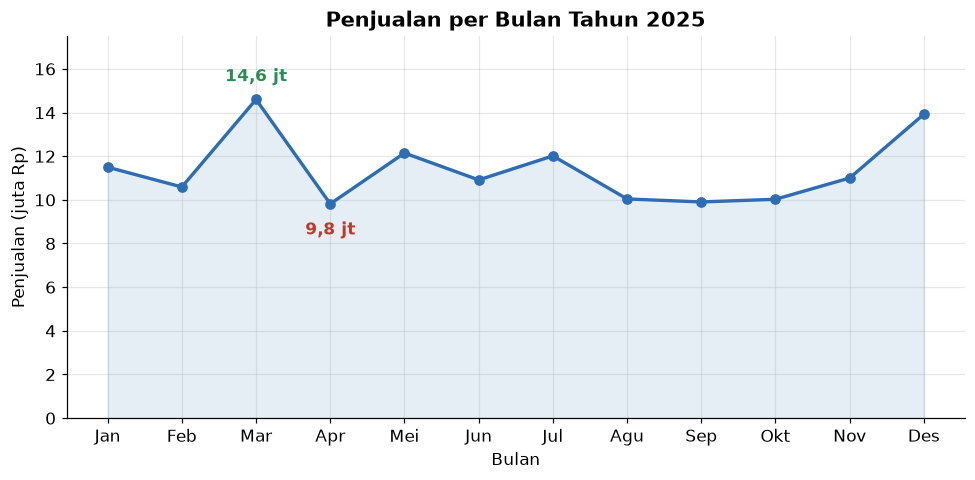

Bulan tertinggi: Mar | 14,6 jt
Bulan terendah : Apr | 9,8 jt
Total 2025     : 136,5 jt


In [3]:
bulan_label = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']

penjualan_bulan = (v25[v25['status'] == 'SELESAI']
                   .groupby('bulan')['pendapatan'].sum()
                   .reindex(range(1, 13), fill_value=0))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(bulan_label, penjualan_bulan / 1e6, marker='o', linewidth=2.2, color='#2E6DB4')
ax.fill_between(bulan_label, penjualan_bulan / 1e6, alpha=0.12, color='#2E6DB4')

i_max, i_min = penjualan_bulan.values.argmax(), penjualan_bulan.values.argmin()
for i, warna, geser in [(i_max, '#2E8B57', 12), (i_min, '#C0392B', -20)]:   # tertinggi di atas titik, terendah di bawah titik
    ax.annotate(rupiah_juta(penjualan_bulan.iloc[i]),
                (bulan_label[i], penjualan_bulan.iloc[i] / 1e6),
                textcoords='offset points', xytext=(0, geser), ha='center',
                color=warna, fontweight='bold')

ax.set_title('Penjualan per Bulan Tahun 2025', fontsize=14, fontweight='bold')
ax.set_xlabel('Bulan'); ax.set_ylabel('Penjualan (juta Rp)')
ax.set_ylim(0, penjualan_bulan.max() / 1e6 * 1.2)
plt.tight_layout()
plt.savefig('output/bagian1_penjualan_per_bulan_2025.png', dpi=150)
plt.show()

print('Bulan tertinggi:', bulan_label[i_max], '|', rupiah_juta(penjualan_bulan.iloc[i_max]))
print('Bulan terendah :', bulan_label[i_min], '|', rupiah_juta(penjualan_bulan.iloc[i_min]))
print('Total 2025     :', rupiah_juta(penjualan_bulan.sum()))

---
## Bagian 2 — 10 produk terlaris tahun 2025
"Terlaris" diukur dari **total unit terjual** (transaksi `SELESAI`). Kode produk `XXX…` (tidak dikenal) tidak diikutkan.

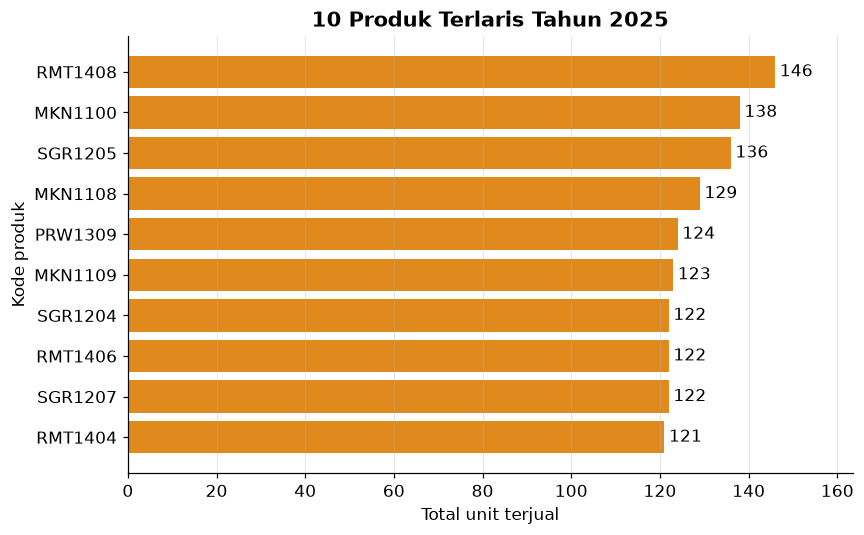

,unit_terjual
kode_produk,
RMT1408,146
MKN1100,138
SGR1205,136
MKN1108,129
PRW1309,124
MKN1109,123
SGR1204,122
RMT1406,122
SGR1207,122


In [4]:
produk = v25[(v25['status'] == 'SELESAI') & (~v25['kode_produk'].str.startswith('XXX'))]
top10 = (produk.groupby('kode_produk')['jumlah'].sum()
               .sort_values(ascending=False).head(10))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top10.index, top10.values, color='#E08A1E')
ax.invert_yaxis()                         # terlaris di paling atas
ax.bar_label(bars, fmt='%d', padding=3)
ax.set_title('10 Produk Terlaris Tahun 2025', fontsize=14, fontweight='bold')
ax.set_xlabel('Total unit terjual'); ax.set_ylabel('Kode produk')
ax.set_xlim(0, top10.max() * 1.12)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig('output/bagian2_top10_produk_2025.png', dpi=150)
plt.show()
top10.to_frame('unit_terjual')

---
## Bagian 3 — Proporsi transaksi berhasil vs gagal/cancel tahun 2025
- **Berhasil** = `SELESAI`
- **Gagal / Cancel** = `BATAL`
- `RETUR` (barang dikembalikan setelah dibeli) ditampilkan sebagai irisan terpisah agar tidak tercampur dengan keduanya.

Yang dihitung adalah **jumlah transaksi**.

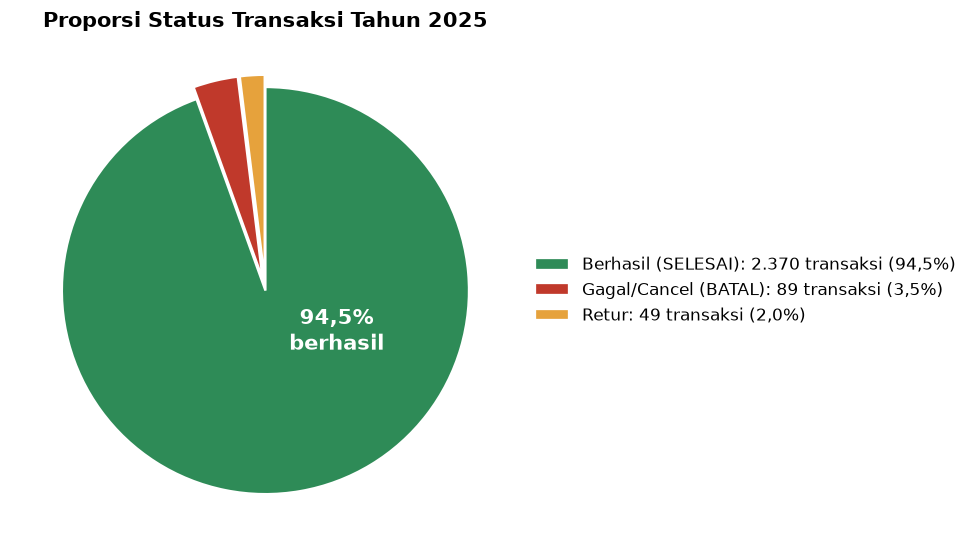

,jumlah_transaksi,persen
status,,
SELESAI,2370,94.50
BATAL,89,3.55
RETUR,49,1.95


In [5]:
status_2025 = d25['status'].value_counts().reindex(['SELESAI', 'BATAL', 'RETUR'])
label = {'SELESAI': 'Berhasil (SELESAI)', 'BATAL': 'Gagal/Cancel (BATAL)', 'RETUR': 'Retur'}

persen = status_2025 / status_2025.sum() * 100
warna = ['#2E8B57', '#C0392B', '#E6A23C']

fig, ax = plt.subplots(figsize=(8, 5.5))
wedges, _ = ax.pie(status_2025.values, colors=warna, startangle=90, counterclock=False,
                   explode=(0, 0.06, 0.06),
                   wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})

# persen irisan kecil tidak muat di dalam pie -> semua keterangan ditaruh di legenda
id_fmt = lambda x: x.replace(',', 'X').replace('.', ',').replace('X', '.')   # format angka Indonesia
legenda = [id_fmt(f"{label[s]}: {n:,} transaksi ({p:.1f}%)")
           for s, n, p in zip(status_2025.index, status_2025.values, persen.values)]
ax.legend(wedges, legenda, loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False)
ax.text(0.35, -0.2, id_fmt(f"{persen['SELESAI']:.1f}%")+'\nberhasil', ha='center', va='center',
        fontsize=14, fontweight='bold', color='white')
ax.set_title('Proporsi Status Transaksi Tahun 2025', fontsize=14, fontweight='bold')
ax.grid(False)
plt.tight_layout()
plt.savefig('output/bagian3_proporsi_status_2025.png', dpi=150, bbox_inches='tight')
plt.show()

status_2025.to_frame('jumlah_transaksi').assign(persen=persen.round(2))

---
## Bagian 4 — Hubungan jumlah beli dengan diskon
Memakai seluruh data (2024–2025) tanpa outlier `jumlah`. Diskon hanya punya 5 level (0, 5, 10, 15, 20 %), jadi titik pada scatter diberi *jitter* (geseran kecil acak) agar tidak menumpuk, dan ditambah boxplot per level diskon.

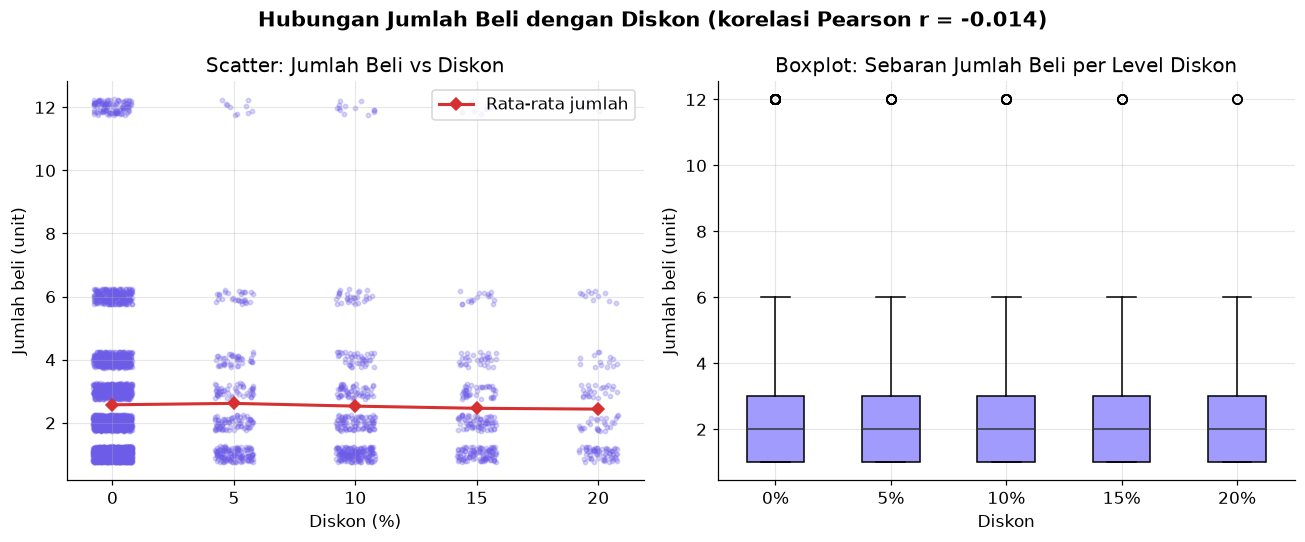

Korelasi Pearson : -0.014
Korelasi Spearman: -0.011


,banyak_transaksi,rata_rata,median
diskon_persen,,,
0.0,3817,2.57,2.0
5.0,343,2.62,2.0
10.0,415,2.53,2.0
15.0,270,2.46,2.0
20.0,143,2.43,2.0


In [6]:
import numpy as np

rng = np.random.default_rng(42)
jitter_x = valid['diskon_persen'] + rng.uniform(-0.8, 0.8, len(valid))
jitter_y = valid['jumlah'] + rng.uniform(-0.25, 0.25, len(valid))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.scatter(jitter_x, jitter_y, s=8, alpha=0.25, color='#6C5CE7')
rata = valid.groupby('diskon_persen')['jumlah'].mean()
ax1.plot(rata.index, rata.values, color='#D63031', marker='D', linewidth=2, label='Rata-rata jumlah')
ax1.set_title('Scatter: Jumlah Beli vs Diskon')
ax1.set_xlabel('Diskon (%)'); ax1.set_ylabel('Jumlah beli (unit)')
ax1.set_xticks(rata.index); ax1.legend()

grup = [valid.loc[valid['diskon_persen'] == k, 'jumlah'] for k in rata.index]
ax2.boxplot(grup, tick_labels=[f'{int(k)}%' for k in rata.index], patch_artist=True,
            boxprops={'facecolor': '#A29BFE'}, medianprops={'color': '#2D3436'})
ax2.set_title('Boxplot: Sebaran Jumlah Beli per Level Diskon')
ax2.set_xlabel('Diskon'); ax2.set_ylabel('Jumlah beli (unit)')

r = valid['jumlah'].corr(valid['diskon_persen'])
fig.suptitle(f'Hubungan Jumlah Beli dengan Diskon (korelasi Pearson r = {r:.3f})',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('output/bagian4_jumlah_vs_diskon.png', dpi=150)
plt.show()

print(f'Korelasi Pearson : {r:.3f}')
print(f"Korelasi Spearman: {valid['jumlah'].corr(valid['diskon_persen'], method='spearman'):.3f}")
valid.groupby('diskon_persen')['jumlah'].agg(banyak_transaksi='count', rata_rata='mean', median='median').round(2)

---
## Kesimpulan
1. **Penjualan bulanan 2025:** lihat angka bulan tertinggi dan terendah pada Bagian 1. Penjualan cenderung naik di Maret dan Desember.
2. **Produk terlaris:** 10 kode produk teratas berdasarkan unit terjual ada di Bagian 2 (`RMT1408` paling atas).
3. **Status transaksi:** sebagian besar transaksi 2025 berhasil; yang dibatalkan dan diretur jumlahnya kecil.
4. **Jumlah vs diskon:** korelasi mendekati nol, artinya **diskon yang lebih besar tidak membuat pelanggan membeli lebih banyak unit**. Rata-rata jumlah beli hampir sama di semua level diskon.